# NFL watchability scoring

Milestone 1 of the [spec](https://claude.ai/code/artifact/f12b8ba8-3a1c-418e-929a-a3dfdb48e0ca): compute the seven signals from nflverse play-by-play, score games against a 2023–2025 reference distribution, and check the ranking against your own judgment.

All logic lives in `watchability.py`; this notebook only runs and inspects it. **Spoiler note:** past seasons show scores; the current-season view shows only matchup, tier and stars.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import watchability as w

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

REFERENCE_SEASONS = [2023, 2024, 2025]
CURRENT_SEASON = 2026

games = w.load_games()                       # pass refresh=True to re-download
pbp = w.load_pbp(REFERENCE_SEASONS + [CURRENT_SEASON])
signals = w.build_signals(pbp, games)
reference = signals[signals.season.isin(REFERENCE_SEASONS)]
scored = w.score(signals, reference)
ref_scored = scored[scored.season.isin(REFERENCE_SEASONS)]
print(f"{len(reference)} reference games, {len(scored) - len(ref_scored)} games in {CURRENT_SEASON} so far")

855 reference games, 80 games in 2026 so far


## Raw signal distributions (reference seasons)

In [2]:
reference[w.SIGNALS].describe().round(2)

,excitement,late_closeness,comeback,explosive,touchdowns,turnovers,stakes
count,855.00,855.00,855.00,855.00,855.00,855.00,855.00
mean,3.83,9.87,0.59,8.78,4.94,0.34,0.27
std,1.57,9.90,0.21,3.33,2.06,0.26,0.29
min,0.75,0.00,0.11,0.00,0.00,0.00,0.00
25%,2.57,0.00,0.42,6.00,3.50,0.15,0.00
50%,3.75,8.05,0.60,9.00,5.00,0.28,0.25
75%,4.90,15.07,0.76,11.00,6.00,0.49,0.35
max,10.44,55.00,1.00,21.50,12.00,1.57,1.20


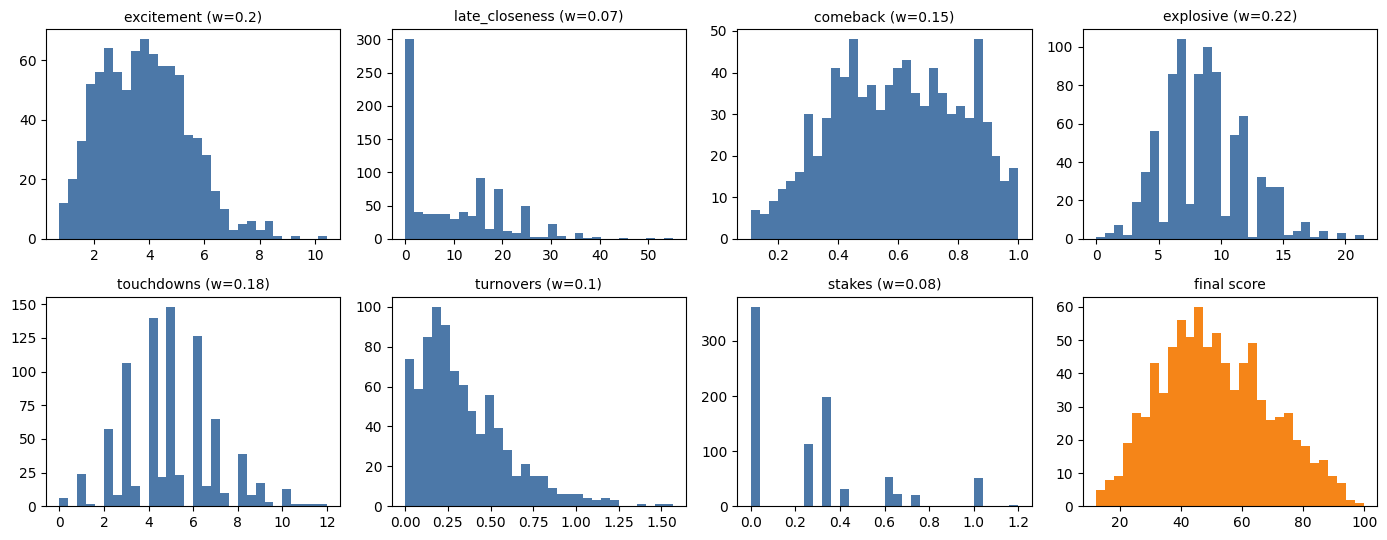

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for ax, s in zip(axes.flat, w.SIGNALS):
    ax.hist(reference[s], bins=30, color="#4C78A8")
    ax.set_title(f"{s} (w={w.WEIGHTS[s]})", fontsize=10)
ax = axes.flat[-1]
ax.hist(ref_scored.score, bins=30, color="#F58518")
ax.set_title("final score", fontsize=10)
fig.tight_layout()

## Are the signals redundant?

High correlation means two signals double-count the same thing. Excitement, closeness and comeback are expected to overlap somewhat.

In [4]:
reference[w.SIGNALS].corr(method="spearman").round(2)

,excitement,late_closeness,comeback,explosive,touchdowns,turnovers,stakes
excitement,1.00,0.88,0.65,0.12,-0.06,0.51,0.06
late_closeness,0.88,1.00,0.61,0.09,-0.03,0.41,0.06
comeback,0.65,0.61,1.00,0.15,0.07,0.32,0.03
explosive,0.12,0.09,0.15,1.00,0.50,-0.05,0.04
touchdowns,-0.06,-0.03,0.07,0.50,1.00,-0.13,0.03
turnovers,0.51,0.41,0.32,-0.05,-0.13,1.00,0.03
stakes,0.06,0.06,0.03,0.04,0.03,0.03,1.00


## Tier calibration

The spec targets 3 **Must watch** games per regular-season week. This shows how the current cutoffs land and what cutoff would hit the target.

In [5]:
reg = ref_scored[ref_scored.game_type == "REG"]
per_week = reg.groupby(["season", "week"]).tier.apply(lambda t: (t == "Must watch").sum())
print("Tier share:", ref_scored.tier.value_counts(normalize=True).round(3).to_dict())
print(f"Must watch per week at cutoff {w.TIERS[0][0]}: mean {per_week.mean():.2f}, median {per_week.median():.0f}")

games_per_week = reg.groupby(["season", "week"]).size().mean()
for target in (2.5, 3, 3.5):
    cutoff = reg.score.quantile(1 - target / games_per_week)
    print(f"  {target} per week  ->  cutoff {cutoff:.1f}")

Tier share: {'Worth it': 0.398, 'Skippable': 0.396, 'Must watch': 0.206}
Must watch per week at cutoff 67: mean 2.96, median 3
  2.5 per week  ->  cutoff 69.6
  3 per week  ->  cutoff 66.4
  3.5 per week  ->  cutoff 64.2


## Best and worst reference games

In [6]:
cols = ["game_id", "away_team", "away_score", "home_team", "home_score", "score", "tier",
        "excitement", "late_closeness", "comeback", "explosive", "touchdowns", "turnovers", "stakes", "big_moment"]
ref_scored.nlargest(15, "score")[cols]

,game_id,away_team,away_score,home_team,home_score,score,tier,excitement,late_closeness,comeback,explosive,touchdowns,turnovers,stakes,big_moment
794,2025_16_LA_SEA,LA,37,SEA,38,99.9,Must watch,8.452879,19.833333,0.987555,17.0,9.0,0.516541,1.00,True
96,2023_07_CLE_IND,CLE,39,IND,38,95.0,Must watch,7.339466,35.000000,0.871601,16.0,9.0,0.943684,0.00,True
589,2025_02_NYG_DAL,NYG,37,DAL,40,94.6,Must watch,10.435559,55.000000,0.811849,15.0,8.0,0.487481,0.35,True
420,2024_09_LA_SEA,LA,26,SEA,20,93.8,Must watch,7.745070,25.050000,0.895240,14.0,6.0,1.173356,0.35,True
349,2024_05_TB_ATL,TB,30,ATL,36,93.1,Must watch,7.165781,21.250000,0.916504,15.0,7.0,0.291629,0.60,True
352,2024_05_BAL_CIN,BAL,41,CIN,38,92.7,Must watch,6.135696,17.766667,0.880164,12.0,10.0,0.601926,0.35,True
738,2025_12_NYG_DET,NYG,27,DET,34,92.7,Must watch,7.878456,24.233333,0.857886,20.0,7.0,1.208807,0.00,True
177,2023_12_BUF_PHI,BUF,34,PHI,37,92.4,Must watch,7.952180,36.083333,0.884445,14.0,9.0,0.501127,0.00,True
518,2024_16_PHI_WAS,PHI,33,WAS,36,92.4,Must watch,5.859671,28.616667,0.961517,10.0,8.0,0.800888,0.75,True
192,2023_13_CIN_JAX,CIN,34,JAX,31,91.4,Must watch,7.721466,28.250000,0.932807,15.0,8.0,0.230682,0.25,True


In [7]:
ref_scored.nsmallest(10, "score")[cols]

,game_id,away_team,away_score,home_team,home_score,score,tier,excitement,late_closeness,comeback,explosive,touchdowns,turnovers,stakes,big_moment
786,2025_15_LV_PHI,LV,0,PHI,31,12.2,Skippable,1.345883,0.0,0.175868,4.0,4.0,0.077810,0.00,False
126,2023_09_ARI_CLE,ARI,0,CLE,27,13.5,Skippable,1.890442,0.0,0.171043,2.0,3.0,0.274659,0.00,False
667,2025_07_LV_KC,LV,0,KC,31,14.0,Skippable,1.091260,0.0,0.174607,3.0,4.0,0.000246,0.35,False
245,2023_17_TEN_HOU,TEN,3,HOU,26,14.1,Skippable,1.393049,0.0,0.314420,5.0,2.0,0.103436,0.35,False
832,2025_18_GB_MIN,GB,3,MIN,16,15.1,Skippable,1.997735,0.0,0.203413,5.0,1.0,0.030251,0.75,False
217,2023_15_NYG_NO,NYG,6,NO,24,15.5,Skippable,2.650944,0.0,0.395732,3.5,3.0,0.005186,0.00,False
120,2023_08_CHI_LAC,CHI,13,LAC,30,16.0,Skippable,1.247945,0.0,0.233263,4.0,4.5,0.056953,0.25,False
303,2024_02_LAC_CAR,LAC,26,CAR,3,16.0,Skippable,1.805551,0.0,0.310783,5.0,3.0,0.227536,0.00,False
326,2024_03_MIA_SEA,MIA,3,SEA,24,16.1,Skippable,2.172374,0.0,0.405516,4.5,3.0,0.116599,0.00,False
247,2023_17_CAR_JAX,CAR,0,JAX,26,16.4,Skippable,2.135744,0.0,0.492855,5.0,1.5,0.127313,0.00,False


## Why it ranked here: points per signal for the top reference game

In [8]:
top = ref_scored.loc[ref_scored.score.idxmax()]
print(top.game_id, top.score)
w.contributions(top)

2025_16_LA_SEA 99.9


explosive         21.7
excitement        19.9
touchdowns        17.3
comeback          14.9
turnovers          7.9
stakes             7.7
late_closeness     5.5
big_moment         5.0
dtype: float64

## Current season, spoiler safe

Matchup, tier and stars only, best first. Change `WEEK` to look at another week.

In [9]:
current = scored[scored.season == CURRENT_SEASON]
WEEK = 5
week = current[current.week == WEEK].sort_values("score", ascending=False)
week.assign(matchup=week.away_team + " @ " + week.home_team)[
    ["matchup", "weekday", "tier", "stars", "playoff", "division", "primetime"]
].reset_index(drop=True)

,matchup,weekday,tier,stars,playoff,division,primetime
0,BUF @ LA,Monday,Must watch,5,False,False,True
1,NYG @ WAS,Sunday,Must watch,4,False,True,False
2,BAL @ ATL,Sunday,Must watch,4,False,False,True
3,SF @ SEA,Sunday,Must watch,4,False,True,False
4,PHI @ JAX,Sunday,Must watch,4,False,False,False
5,CLE @ NYJ,Sunday,Worth it,4,False,False,False
6,TB @ DAL,Thursday,Worth it,3,False,False,True
7,IND @ PIT,Sunday,Worth it,3,False,False,False
8,DEN @ LAC,Sunday,Worth it,3,False,True,False
9,DET @ ARI,Sunday,Worth it,3,False,False,False


## Blind check: does the model agree with you?

1. Run the next cell. It lists one week's games in random order with no scores. It defaults to the latest full week of the current season; set `CHECK_SEASON` / `CHECK_WEEK` for any other week.
2. Put the game_ids in `my_ranking`, best first, from memory or after skimming highlights.
3. Run the cell after it to reveal the model's ranking and scores. The spec's bar is at least 4 of your top 5 in the model's top 5.

In [10]:
CHECK_SEASON = CURRENT_SEASON
week_sizes = scored[scored.season == CHECK_SEASON].groupby("week").size()
CHECK_WEEK = week_sizes[week_sizes >= 10].index.max()   # latest full week; set a number to override

check = scored[(scored.season == CHECK_SEASON) & (scored.week == CHECK_WEEK)]
print(f"{CHECK_SEASON} week {CHECK_WEEK}: {len(check)} games")
check.sample(frac=1, random_state=0).assign(matchup=lambda d: d.away_team + " @ " + d.home_team)[
    ["game_id", "matchup"]
].reset_index(drop=True)

2026 week 5: 15 games


,game_id,matchup
0,2026_05_PHI_JAX,PHI @ JAX
1,2026_05_CLE_NYJ,CLE @ NYJ
2,2026_05_HOU_TEN,HOU @ TEN
3,2026_05_NYG_WAS,NYG @ WAS
4,2026_05_BUF_LA,BUF @ LA
5,2026_05_LV_NE,LV @ NE
6,2026_05_CHI_GB,CHI @ GB
7,2026_05_BAL_ATL,BAL @ ATL
8,2026_05_DEN_LAC,DEN @ LAC
9,2026_05_IND_PIT,IND @ PIT


In [11]:
my_ranking = [
    "2026_05_SF_SEA",
    "2026_05_TB_DAL",
    "2026_05_BUF_LA",
    "2026_05_BAL_ATL",
    "2026_05_LV_NE",
    "2026_05_DET_ARI",
    "2026_05_CIN_MIA",
    "2026_05_NYG_WAS"
]

if len(my_ranking) >= 5:
    print(f"Overlap in top 5: {w.top_k_overlap(my_ranking, check)} of 5")
    display(check.sort_values("score", ascending=False)[cols].head(8))
else:
    print("Fill in my_ranking (at least 5 game_ids) to run the check.")

Overlap in top 5: 3 of 5


,game_id,away_team,away_score,home_team,home_score,score,tier,excitement,late_closeness,comeback,explosive,touchdowns,turnovers,stakes,big_moment
933,2026_05_BUF_LA,BUF,37,LA,34,89.8,Must watch,7.997792,33.083333,0.776014,16.0,9.0,0.219458,0.25,True
928,2026_05_NYG_WAS,NYG,27,WAS,27,85.4,Must watch,7.104228,21.183333,0.967973,14.0,6.0,0.391408,0.35,False
932,2026_05_BAL_ATL,BAL,30,ATL,23,83.1,Must watch,6.371439,27.916667,0.951557,10.0,5.0,0.834235,0.25,True
931,2026_05_SF_SEA,SF,32,SEA,29,75.2,Must watch,5.783868,20.000000,0.761201,7.0,6.0,1.345501,0.35,True
920,2026_05_PHI_JAX,PHI,17,JAX,19,67.4,Must watch,7.331620,30.000000,0.803707,8.0,4.0,0.411686,0.00,True
925,2026_05_CLE_NYJ,CLE,12,NYJ,17,66.0,Worth it,6.168427,25.000000,0.783919,10.0,3.0,0.897747,0.00,False
919,2026_05_TB_DAL,TB,24,DAL,16,62.1,Worth it,3.770052,5.500000,0.884560,10.0,5.0,0.426682,0.25,False
926,2026_05_IND_PIT,IND,22,PIT,34,52.4,Worth it,4.124509,8.416667,0.565853,12.0,5.0,0.020592,0.00,False


## Save scores for the ingestion job to compare against

In [12]:
out = w.DATA_DIR.parent / "scored_games.csv"
scored.drop(columns=[c for c in scored.columns if c.startswith("pct_")]).to_csv(out, index=False)
print(f"Wrote {len(scored)} games to {out}")

Wrote 935 games to C:\Users\zhtli\Documents\sports-larp\data\scored_games.csv
